<p style="text-align:center">
    <a href="https://skills.network/?utm_medium=Exinfluencer&utm_source=Exinfluencer&utm_content=000026UJ&utm_term=10006555&utm_id=NA-SkillsNetwork-Channel-SkillsNetworkCoursesIBMDeveloperSkillsNetworkPY0220ENSkillsNetwork900-2022-01-01" target="_blank">
    <img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/assets/logos/SN_web_lightmode.png" width="200" alt="Skills Network Logo">
    </a>
</p>


# Tesla and GameStop: Historical Stock Price and Revenue Analysis

IBM Python Project for Data Science — Final Assignment


Extracting essential data from a dataset and displaying it is a necessary part of data science; therefore individuals can make correct decisions based on the data. In this assignment, you will extract some stock data, you will then display this data in a graph.


<h2>Table of Contents</h2>
<div class="alert alert-block alert-info" style="margin-top: 20px">
    <ul>
        <li>Define a Function that Makes a Graph</li>
        <li>Question 1: Use yfinance to Extract Stock Data</li>
        <li>Question 2: Use Webscraping to Extract Tesla Revenue Data</li>
        <li>Question 3: Use yfinance to Extract Stock Data</li>
        <li>Question 4: Use Webscraping to Extract GME Revenue Data</li>
        <li>Question 5: Plot Tesla Stock Graph</li>
        <li>Question 6: Plot GameStop Stock Graph</li>
    </ul>
<p>
    Estimated Time Needed: <strong>30 min</strong></p>
</div>

<hr>


### Data and reproducibility notes

All six exercises below are completed using the official lab template. Stock data is retrieved with `yfinance`, and quarterly revenues are scraped from the course-provided HTML snapshots. `Close` is explicitly adjusted for splits and dividends, matching the lab convention. Live stock history can change when the provider revises adjustment factors.

The dashboard follows the lab's historical cutoffs (stock prices through June 14, 2021; revenues through April 30, 2021). Tesla's revenue snapshot extends to 2022, while GameStop's ends in April 2020; missing subsequent quarters are not invented. The observations below describe the plotted data and do not establish causation.


***Note***:- If you are working Locally using anaconda, please uncomment the following code and execute it.


In [1]:
# Optional setup, if dependencies are missing:
# %pip install yfinance pandas requests beautifulsoup4 plotly matplotlib nbformat


In [2]:
# Dependencies are installed in the execution environment.


In [3]:
import yfinance as yf
import pandas as pd
import requests
from bs4 import BeautifulSoup
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import matplotlib.pyplot as plt
from IPython.display import display, HTML

pd.set_option('display.max_columns', None)


In [4]:
# Embed the interactive chart directly, without an external iframe file.
# A static chart is also displayed so notebook viewers can show both panels.
import plotly.io as pio
pio.renderers.default = 'notebook'


In Python, you can ignore warnings using the warnings module. You can use the filterwarnings function to filter or ignore specific warning messages or categories.


In [5]:
# Keep warnings visible so data or API issues are not hidden.


## Define Graphing Function


In this section, we define the function `make_graph`. **You don't have to know how the function works, you should only care about the inputs. It takes a dataframe with stock data (dataframe must contain Date and Close columns), a dataframe with revenue data (dataframe must contain Date and Revenue columns), and the name of the stock.**


In [6]:
def make_graph(stock_data, revenue_data, stock):
    prices = stock_data.copy()
    revenues = revenue_data.copy()
    prices['Date'] = pd.to_datetime(prices['Date']).dt.tz_localize(None)
    revenues['Date'] = pd.to_datetime(revenues['Date'])
    # Match the historical window in the supplied lab.
    prices = prices.loc[prices['Date'] <= pd.Timestamp('2021-06-14')].sort_values('Date')
    revenues = revenues.loc[revenues['Date'] <= pd.Timestamp('2021-04-30')].sort_values('Date')
    revenues['Revenue'] = pd.to_numeric(revenues['Revenue'], errors='raise')
    assert not prices.empty and not revenues.empty

    fig = make_subplots(rows=2, cols=1, shared_xaxes=True,
                        subplot_titles=('Historical Share Price', 'Historical Revenue'),
                        vertical_spacing=0.18)
    fig.add_trace(go.Scatter(x=prices['Date'], y=prices['Close'],
                            name='Share price', line=dict(color='#2563eb')), row=1, col=1)
    fig.add_trace(go.Scatter(x=revenues['Date'], y=revenues['Revenue'],
                            name='Quarterly revenue', line=dict(color='#16a34a')), row=2, col=1)
    fig.update_xaxes(title_text='Date', row=1, col=1)
    fig.update_xaxes(title_text='Date', row=2, col=1)
    fig.update_yaxes(title_text='Price (USD, adjusted)', row=1, col=1)
    fig.update_yaxes(title_text='Revenue (USD millions)', row=2, col=1)
    fig.update_layout(title=stock + ' — Historical Stock Price and Revenue',
                      height=850, template='plotly_white', showlegend=False,
                      xaxis_rangeslider_visible=True)
    # Inline JavaScript makes the interactive output self-contained.
    display(HTML(fig.to_html(full_html=False, include_plotlyjs=True)))

    static_fig, axes = plt.subplots(2, 1, figsize=(11, 8), constrained_layout=True)
    axes[0].plot(prices['Date'], prices['Close'], color='#2563eb', linewidth=1.2)
    axes[0].set(title=stock + ' — Historical Share Price', ylabel='Price (USD, adjusted)', xlabel='Date')
    axes[1].plot(revenues['Date'], revenues['Revenue'], color='#16a34a', linewidth=1.5)
    axes[1].set(title=stock + ' — Historical Revenue', ylabel='Revenue (USD millions)', xlabel='Date')
    for ax in axes:
        ax.grid(alpha=0.2)
    plt.show()


Use the make_graph function that we’ve already defined. You’ll need to invoke it in questions 5 and 6 to display the graphs and create the dashboard. 
> **Note: You don’t need to redefine the function for plotting graphs anywhere else in this notebook; just use the existing function.**


## Question 1: Use yfinance to Extract Stock Data


Using the `Ticker` function enter the ticker symbol of the stock we want to extract data on to create a ticker object. The stock is Tesla and its ticker symbol is `TSLA`.


In [7]:
tesla = yf.Ticker('TSLA')


Using the ticker object and the function `history` extract stock information and save it in a dataframe named `tesla_data`. Set the `period` parameter to ` "max" ` so we get information for the maximum amount of time.


In [8]:
# Explicit auto_adjust=True matches the adjusted historical Close in the lab.
tesla_data = tesla.history(period='max', auto_adjust=True)
assert not tesla_data.empty, 'No Tesla stock data was returned.'


**Reset the index** using the `reset_index(inplace=True)` function on the tesla_data DataFrame and display the first five rows of the `tesla_data` dataframe using the `head` function. Take a screenshot of the results and code from the beginning of Question 1 to the results below.


In [9]:
tesla_data.reset_index(inplace=True)
display(tesla_data.head())


,Date,Open,High,Low,Close,Volume,Dividends,Stock Splits
0,2010-06-29 00:00:00-04:00,1.266667,1.666667,1.169333,1.592667,281494500,0.0,0.0
1,2010-06-30 00:00:00-04:00,1.719333,2.028000,1.553333,1.588667,257806500,0.0,0.0
2,2010-07-01 00:00:00-04:00,1.666667,1.728000,1.351333,1.464000,123282000,0.0,0.0
3,2010-07-02 00:00:00-04:00,1.533333,1.540000,1.247333,1.280000,77097000,0.0,0.0
4,2010-07-06 00:00:00-04:00,1.333333,1.333333,1.055333,1.074000,103003500,0.0,0.0


## Question 2: Use Webscraping to Extract Tesla Revenue Data


Use the `requests` library to download the webpage https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-PY0220EN-SkillsNetwork/labs/project/revenue.htm Save the text of the response as a variable named `html_data`.


In [10]:
tesla_url = 'https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-PY0220EN-SkillsNetwork/labs/project/revenue.htm'
response = requests.get(tesla_url, timeout=60)
response.raise_for_status()
html_data = response.text


Parse the downloaded HTML text with BeautifulSoup and the built-in `html.parser` parser.


In [11]:
soup = BeautifulSoup(html_data, 'html.parser')


Using `BeautifulSoup` or the `read_html` function extract the table with `Tesla Quarterly Revenue` and store it into a dataframe named `tesla_revenue`. The dataframe should have columns `Date` and `Revenue`.


<details><summary>Step-by-step instructions</summary>

```

Here are the step-by-step instructions:

1. Find All Tables: Start by searching for all HTML tables on a webpage using `soup.find_all('table')`.
2. Identify the Relevant Table: then loops through each table. If a table contains the text “Tesla Quarterly Revenue,”, select that table.
3. Initialize a DataFrame: Create an empty Pandas DataFrame called `tesla_revenue` with columns “Date” and “Revenue.”
4. Loop Through Rows: For each row in the relevant table, extract the data from the first and second columns (date and revenue).
5. Clean Revenue Data: Remove dollar signs and commas from the revenue value.
6. Add Rows to DataFrame: Create a new row in the DataFrame with the extracted date and cleaned revenue values.
7. Repeat for All Rows: Continue this process for all rows in the table.

```
</details>


<details><summary>Click here if you need help locating the table</summary>

```
    
Below is the code to isolate the table, you will now need to loop through the rows and columns like in the previous lab
    
soup.find_all("tbody")[1]
    
If you want to use the read_html function the table is located at index 1

We are focusing on quarterly revenue in the lab.
> Note: Instead of using the deprecated pd.append() method, consider using pd.concat([df, pd.DataFrame], ignore_index=True).
```

</details>


In [12]:
tesla_table = next(table for table in soup.find_all('table')
                   if 'Tesla Quarterly Revenue' in table.get_text())
rows = []
for row in tesla_table.find_all('tr'):
    cells = row.find_all('td')
    if len(cells) == 2:
        rows.append({'Date': cells[0].get_text(strip=True),
                     'Revenue': cells[1].get_text(strip=True)})
tesla_revenue = pd.DataFrame(rows, columns=['Date', 'Revenue'])


Execute the following line to remove the comma and dollar sign from the `Revenue` column. 


In [13]:
tesla_revenue['Revenue'] = tesla_revenue['Revenue'].str.replace(r'[$,]', '', regex=True)


Execute the following lines to remove an null or empty strings in the Revenue column.


In [14]:
tesla_revenue.dropna(subset=['Date', 'Revenue'], inplace=True)
tesla_revenue = tesla_revenue.loc[tesla_revenue['Revenue'].str.strip().ne('')].copy()
tesla_revenue['Date'] = pd.to_datetime(tesla_revenue['Date'])
tesla_revenue['Revenue'] = pd.to_numeric(tesla_revenue['Revenue'], errors='raise')


Display the last 5 row of the `tesla_revenue` dataframe using the `tail` function. Take a screenshot of the results.


In [15]:
display(tesla_revenue.tail())


,Date,Revenue
48,2010-09-30,31
49,2010-06-30,28
50,2010-03-31,21
52,2009-09-30,46
53,2009-06-30,27


## Question 3: Use yfinance to Extract Stock Data


Using the `Ticker` function enter the ticker symbol of the stock we want to extract data on to create a ticker object. The stock is GameStop and its ticker symbol is `GME`.


In [16]:
gamestop = yf.Ticker('GME')


Using the ticker object and the function `history` extract stock information and save it in a dataframe named `gme_data`. Set the `period` parameter to ` "max" ` so we get information for the maximum amount of time.


In [17]:
gme_data = gamestop.history(period='max', auto_adjust=True)
assert not gme_data.empty, 'No GameStop stock data was returned.'


**Reset the index** using the `reset_index(inplace=True)` function on the gme_data DataFrame and display the first five rows of the `gme_data` dataframe using the `head` function. Take a screenshot of the results and code from the beginning of Question 3 to the results below.


In [18]:
gme_data.reset_index(inplace=True)
display(gme_data.head())


,Date,Open,High,Low,Close,Volume,Dividends,Stock Splits
0,2002-02-13 00:00:00-05:00,1.620128,1.693350,1.603296,1.691666,76216000,0.0,0.0
1,2002-02-14 00:00:00-05:00,1.712707,1.716074,1.670626,1.683250,11021600,0.0,0.0
2,2002-02-15 00:00:00-05:00,1.683250,1.687458,1.658001,1.674834,8389600,0.0,0.0
3,2002-02-19 00:00:00-05:00,1.666418,1.666418,1.578047,1.607504,7410400,0.0,0.0
4,2002-02-20 00:00:00-05:00,1.615920,1.662209,1.603295,1.662209,6892800,0.0,0.0


## Question 4: Use Webscraping to Extract GME Revenue Data


Use the `requests` library to download the webpage https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-PY0220EN-SkillsNetwork/labs/project/stock.html. Save the text of the response as a variable named `html_data_2`.


In [19]:
gme_url = 'https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-PY0220EN-SkillsNetwork/labs/project/stock.html'
response_2 = requests.get(gme_url, timeout=60)
response_2.raise_for_status()
html_data_2 = response_2.text


Parse the html data using `beautiful_soup` using parser i.e `html5lib` or `html.parser`.


In [20]:
soup_2 = BeautifulSoup(html_data_2, 'html.parser')


Using `BeautifulSoup` or the `read_html` function extract the table with `GameStop Quarterly Revenue` and store it into a dataframe named `gme_revenue`. The dataframe should have columns `Date` and `Revenue`. Make sure the comma and dollar sign is removed from the `Revenue` column.


> **Note: Use the method similar to what you did in question 2.**  


<details><summary>Click here if you need help locating the table</summary>

```
    
Below is the code to isolate the table, you will now need to loop through the rows and columns like in the previous lab
    
soup.find_all("tbody")[1]
    
If you want to use the read_html function the table is located at index 1


```

</details>


In [21]:
gme_table = next(table for table in soup_2.find_all('table')
                 if 'GameStop Quarterly Revenue' in table.get_text())
rows = []
for row in gme_table.find_all('tr'):
    cells = row.find_all('td')
    if len(cells) == 2:
        rows.append({'Date': cells[0].get_text(strip=True),
                     'Revenue': cells[1].get_text(strip=True)})
gme_revenue = pd.DataFrame(rows, columns=['Date', 'Revenue'])
gme_revenue['Revenue'] = gme_revenue['Revenue'].str.replace(r'[$,]', '', regex=True)
gme_revenue.dropna(subset=['Date', 'Revenue'], inplace=True)
gme_revenue = gme_revenue.loc[gme_revenue['Revenue'].str.strip().ne('')].copy()
gme_revenue['Date'] = pd.to_datetime(gme_revenue['Date'])
gme_revenue['Revenue'] = pd.to_numeric(gme_revenue['Revenue'], errors='raise')


Display the last five rows of the `gme_revenue` dataframe using the `tail` function. Take a screenshot of the results.


In [22]:
display(gme_revenue.tail())


,Date,Revenue
57,2006-01-31,1667
58,2005-10-31,534
59,2005-07-31,416
60,2005-04-30,475
61,2005-01-31,709


## Question 5: Plot Tesla Stock Graph


Use the `make_graph` function to graph the Tesla Stock Data, also provide a title for the graph. Note the graph will only show data upto June 2021.


<details><summary>Hint</summary>

```

You just need to invoke the make_graph function with the required parameter to print the graphs.The structure to call the `make_graph` function is `make_graph(tesla_data, tesla_revenue, 'Tesla')`.

```
    
</details>


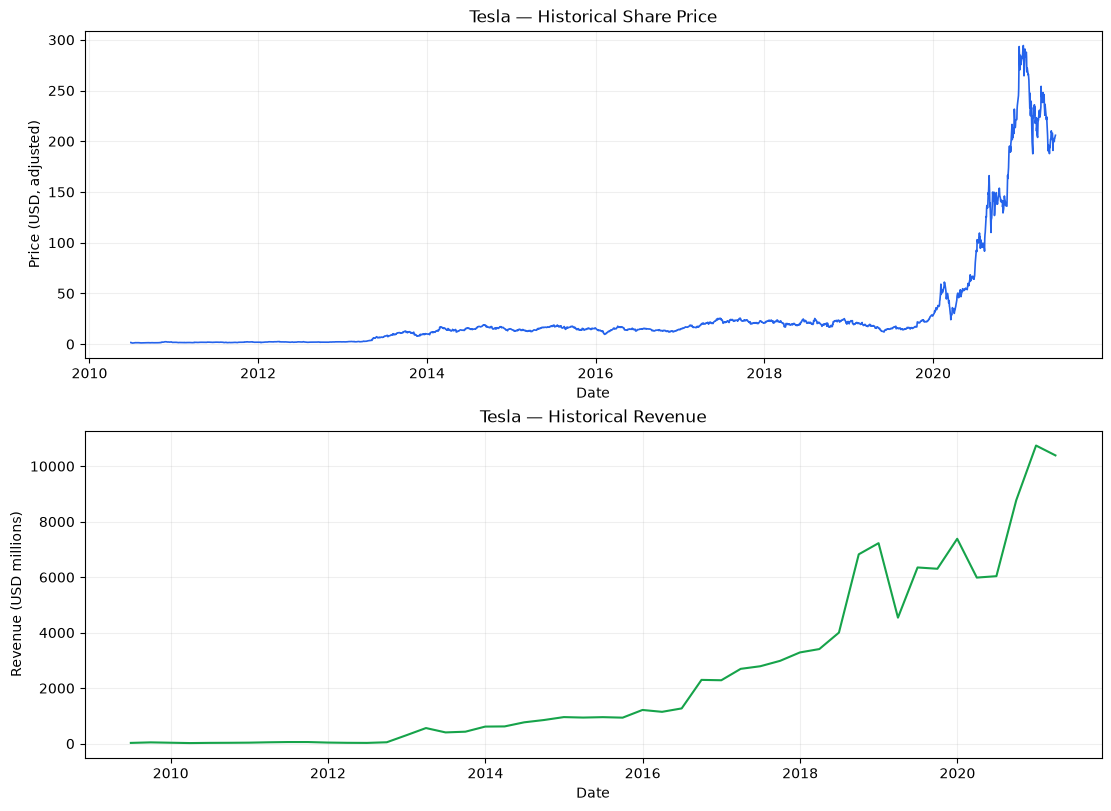

In [23]:
make_graph(tesla_data, tesla_revenue, 'Tesla')


## Question 6: Plot GameStop Stock Graph


Use the `make_graph` function to graph the GameStop Stock Data, also provide a title for the graph. The structure to call the `make_graph` function is `make_graph(gme_data, gme_revenue, 'GameStop')`. Note the graph will only show data upto June 2021.


<details><summary>Hint</summary>

```

You just need to invoke the make_graph function with the required parameter to print the graphs.The structure to call the `make_graph` function is `make_graph(gme_data, gme_revenue, 'GameStop')`

```
    
</details>


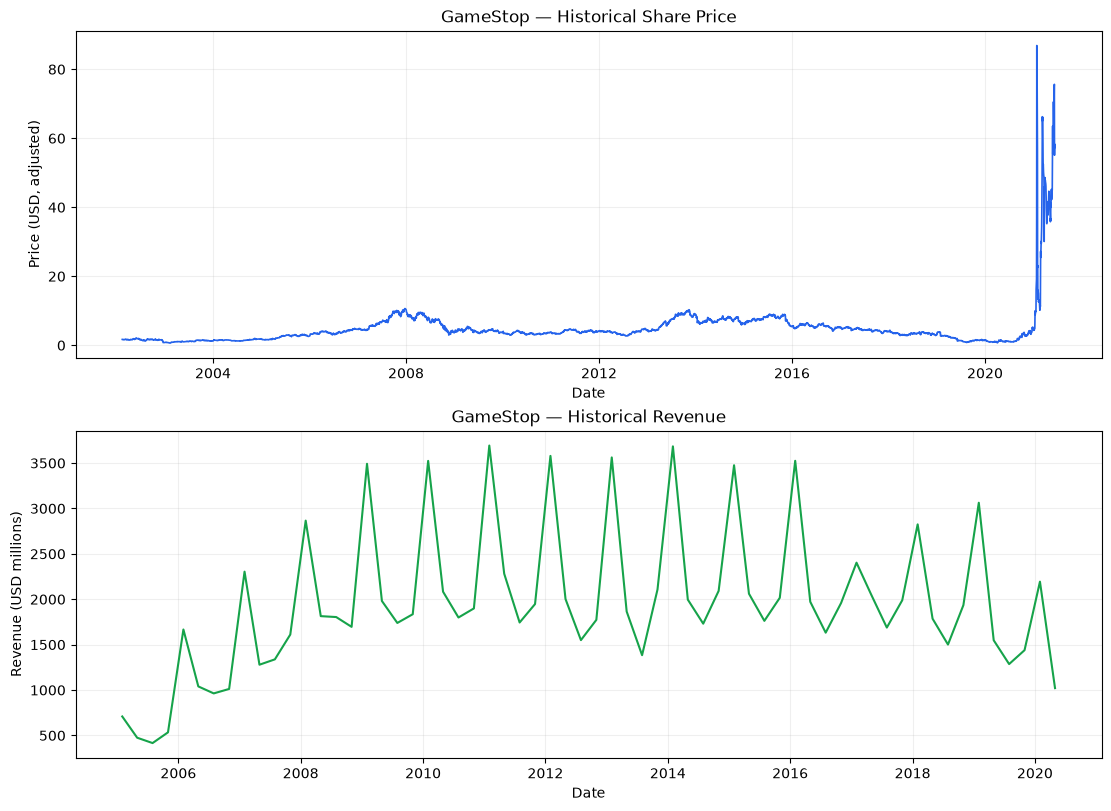

In [24]:
make_graph(gme_data, gme_revenue, 'GameStop')


## Observations and assignment answers

**Tesla:** Between 2018 and 2021, both revenue and stock price showed strong overall growth, although neither series increased monotonically.

**GameStop:** The stock price surged sharply around 2021, but the supplied revenue series does not show a similar increase. Its revenue snapshot ends in April 2020, so it cannot establish what happened to revenue during 2021 or explain the stock-price surge.

## Sources

- [Official IBM Skills Network lab template](https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-PY0220EN-SkillsNetwork/labs/project/Final%20Assignment.ipynb)
- [Tesla quarterly revenue snapshot](https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-PY0220EN-SkillsNetwork/labs/project/revenue.htm)
- [GameStop quarterly revenue snapshot](https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-PY0220EN-SkillsNetwork/labs/project/stock.html)
- [yfinance documentation](https://ranaroussi.github.io/yfinance/)
- [Beautiful Soup parser documentation](https://www.crummy.com/software/BeautifulSoup/bs4/doc/)


<h2>About the Authors:</h2> 

<a href="https://www.linkedin.com/in/joseph-s-50398b136/">Joseph Santarcangelo</a> has a PhD in Electrical Engineering, his research focused on using machine learning, signal processing, and computer vision to determine how videos impact human cognition. Joseph has been working for IBM since he completed his PhD.


## <h3 align="center"> © IBM Corporation 2020. All rights reserved. <h3/>

```toggle ## Change Log
```
```toggle | Date (YYYY-MM-DD) | Version | Changed By    | Change Description        |
```
```toggle | ----------------- | ------- | ------------- | ------------------------- |
```
```toggle | 2022-02-28        | 1.2     | Lakshmi Holla | Changed the URL of GameStop |
```
```toggle | 2020-11-10        | 1.1     | Malika Singla | Deleted the Optional part |
```
```toggle | 2020-08-27        | 1.0     | Malika Singla | Added lab to GitLab       |
```
